# 01 · Exploratory analysis: UK lending losses and the economy

**Question for the project:** if the UK enters the Bank of England's 2025 stress scenario, how much would UK lenders lose on credit cards, other consumer credit, mortgages and corporate lending?

**This notebook** examines the data before any model is fitted:

1. How loss rates are built, and whether the raw series can be trusted (reporting breaks, one-off spikes)
2. How each portfolio behaved through the early-1990s tail, the 2008–10 crisis and COVID
3. Which economic variables move with losses, and with what lag
4. Whether the series are stationary, which decides how the regressions must be specified
5. Where the 2025 stress scenario sits relative to anything in the history: **does it ask the models to extrapolate?**

Every decision taken here is listed in the findings table at the end and carried into notebook 02.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss

from ukstress.config import BCST_PATHS_FILE, PORTFOLIOS
from ukstress.ingest.build_panel import build_panel
from ukstress.ingest.readers import read_bcst_paths
from ukstress.viz import (
    BLUE, GREY, ORANGE, PORTFOLIO_COLOURS, fig_title, save, set_style, shade_recessions, subtitle,
)

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)

panel = build_panel()  # rebuilt from raw files, validated by the Pandera contract
t = panel.index.to_timestamp(how="end")
LABEL = {p: spec["label"] for p, spec in PORTFOLIOS.items()}
print(f"{len(panel)} quarters: {panel.index[0]} to {panel.index[-1]}")

133 quarters: 1993Q2 to 2026Q2


## 1. Data and the loss-rate definition

| Source | Series | Frequency |
|---|---|---|
| Bank of England, Bankstats C2.1 / database | Write-offs of sterling lending, net of recoveries (£m) | Quarterly from 1993 |
| Bank of England database | Amounts outstanding to compare with write-offs (£m) | Quarterly from 1993 |
| ONS | Unemployment (MGSX), real GDP (ABMI), CPI inflation (D7G7) | Quarterly |
| Bank of England | Bank Rate (IUQABEDR), 2-year fixed mortgage rate (IUMBV34) | Quarterly average |
| HM Land Registry | UK House Price Index | Monthly → quarterly mean |
| Bank of England | 2025 Bank Capital Stress Test variable paths | Quarterly, 2025–29 |

**Loss rate** for portfolio *p* in quarter *t*, annualised, as the Bank of England advises (write-offs compared with the balance at the end of the *previous* quarter):

$$LR_{p,t} = 400 \times \frac{\text{write-offs}_{p,t}}{\text{balance}_{p,t-1}}\ \%$$

Write-offs are the realised end of the credit cycle. They are not impairment charges (IFRS 9 provisions are booked earlier), so they should **lag** the economy. Section 4 tests that.

In [2]:
lr = panel[[f"lr_{p}" for p in PORTFOLIOS]].rename(columns=lambda c: c[3:])
lr.describe().T[["mean", "std", "min", "50%", "max"]].rename(index=LABEL).round(2)

,mean,std,min,50%,max
Credit cards,3.62,2.33,1.09,2.90,14.78
Other consumer credit,2.38,1.20,0.55,2.26,8.16
Mortgages,0.05,0.06,-0.00,0.03,0.36
Corporate (PNFC),0.72,0.64,0.08,0.46,3.12


## 2. Can the raw series be trusted?

### 2a. Reporting-population breaks in the balances
A real lending book does not grow 30% in one quarter. Jumps like that mean the set of reporting institutions changed (for example building societies converting to banks, or building societies joining Bank of England reporting in 2008). If the balance jumps but write-offs are reported by a different population, the loss rate shifts for an accounting reason, not an economic one.

In [3]:
bal = panel[[f"bal_{p}" for p in PORTFOLIOS]].rename(columns=lambda c: c[4:])
qoq = 100 * bal.pct_change()
breaks = qoq[qoq.abs() > 10].stack().dropna().rename("balance change q/q, %").to_frame()
breaks["loss rate before (4q avg)"] = [lr[p].shift(1).rolling(4).mean().loc[q] for q, p in breaks.index]
breaks["loss rate after (4q avg)"] = [lr[p].shift(-3).rolling(4).mean().loc[q] for q, p in breaks.index]
breaks.round(2)

balance change q/q, %  loss rate before (4q avg)  loss rate after (4q avg)
quarter                                                                                        
1995Q3  mortgage                     16.07                       0.15                      0.13
1997Q2  mortgage                     61.45                       0.10                      0.11
1997Q3  mortgage                     12.57                       0.09                      0.10
        corporate                    10.58                       1.09                      0.86
2007Q4  mortgage                     33.55                       0.03                      0.03
        corporate                    10.51                       0.27                      0.28
2008Q4  credit_card                 -10.62                       6.53                      8.85
2009Q2  mortgage                     12.44                       0.08                      0.11
2010Q1  credit_card                  27.62                       9.22                      9.88
        mortgage                     16.31                       0.12                      0.07
2013Q1  credit_card                 -15.77                       4.12                      3.75
2020Q2  credit_card                 -10.58                       2.81                      2.91

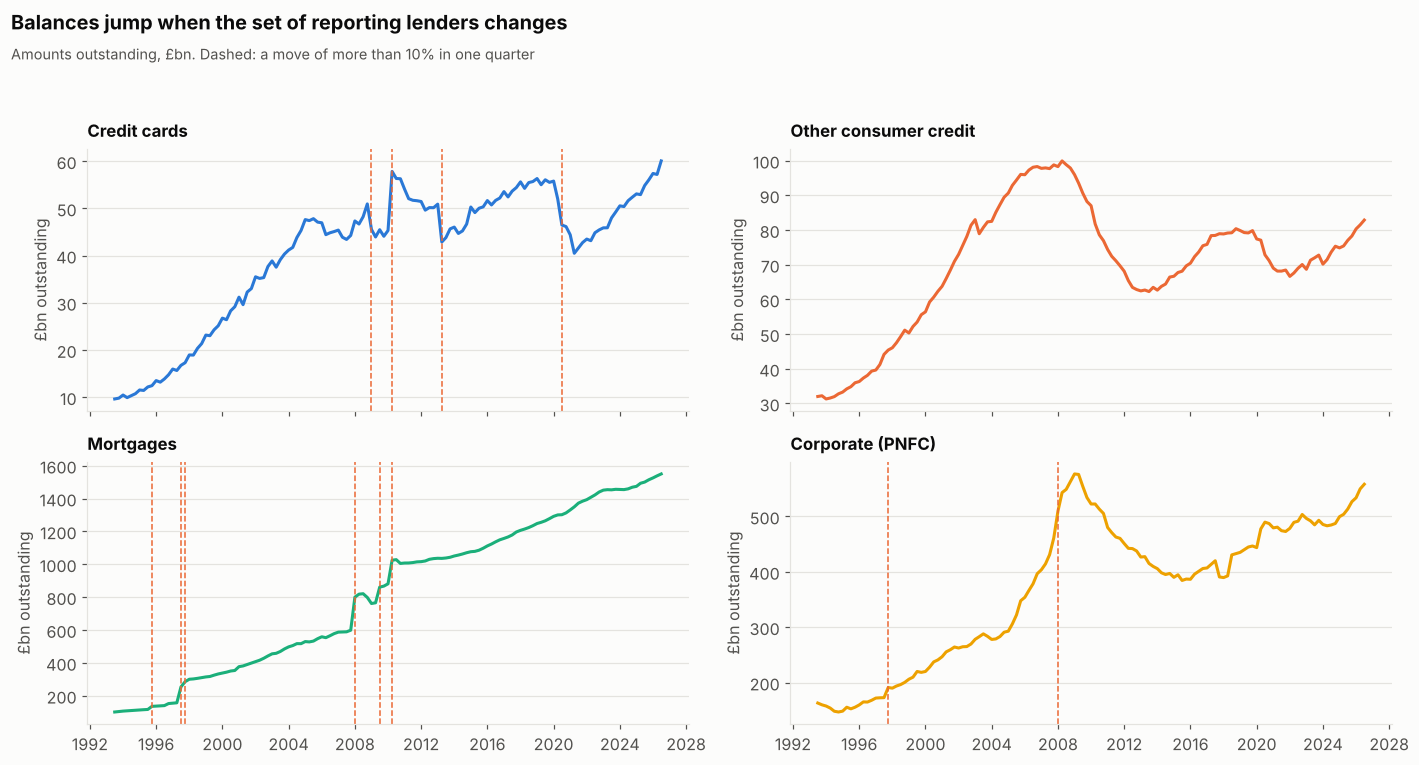

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, p in zip(axes.flat, PORTFOLIOS):
    ax.plot(t, bal[p] / 1000, color=PORTFOLIO_COLOURS[p])
    for q in breaks.index.get_level_values(0)[breaks.index.get_level_values(1) == p]:
        ax.axvline(q.end_time, color=ORANGE, lw=1, ls="--")
    ax.set_title(LABEL[p], fontsize=11, pad=8)
    ax.set_ylabel("£bn outstanding")
fig_title(fig, "Balances jump when the set of reporting lenders changes",
          "Amounts outstanding, £bn. Dashed: a move of more than 10% in one quarter")
save(fig, "01_balance_breaks")
fig

**Reading:** the mortgage series has the largest breaks: 1997 Q2 (+61%, the 1997 wave of building society conversions to banks) and 2007 Q4 (+34%). Credit cards jump in 2010 Q1 and fall in 2013 Q1. Not every large move is a break: the 2020 Q2 card fall (−11%) is households paying down cards in lockdown, which the economy explains. A loss rate is a ratio, so a break only matters if it moves the ratio's *level*. At most breaks the four-quarter loss rate barely changes (mortgages 1997 Q2: 0.10% → 0.11%; 2007 Q4: 0.03% → 0.03%), which suggests write-offs and balances moved together when the reporting population changed. The exceptions (cards 2008 Q4 and 2010 Q1) fall inside the 2008–10 cycle, where a reporting effect cannot be separated from the economy by eye. **Decision:** no splicing or dropping. Test step dummies at the 2010 Q1 and 2013 Q1 card breaks in the model notebooks (a Chow-type test).

### 2b. One-off spikes in write-offs
Quarterly write-offs are lumpy: lenders sell or write off portfolios in blocks. A robust z-score (distance from a rolling median in units of median absolute deviation) flags quarters that are implausible as an economic signal.

In [5]:
def robust_z(s: pd.Series, window: int = 9) -> pd.Series:
    med = s.rolling(window, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=5).median()
    return (s - med) / (1.4826 * mad)

z = lr.apply(robust_z)
spikes = z[z > 4].stack().dropna().rename("robust z").to_frame()
spikes["loss rate %"] = [lr.loc[q, p] for q, p in spikes.index]
spikes["rolling median %"] = [lr[p].rolling(9, center=True, min_periods=5).median().loc[q] for q, p in spikes.index]
spikes.round(2)

robust z  loss rate %  rolling median %
quarter                                                        
1993Q2  credit_card       107.19         6.81              1.84
1993Q3  credit_card         8.13         2.53              1.83
1993Q4  other_consumer      4.88         3.77              2.48
        corporate          16.95         2.37              1.99
1994Q1  corporate           5.14         2.53              1.99
1995Q4  corporate           7.08         3.12              1.45
2002Q1  other_consumer      6.26         2.87              2.28
2003Q1  credit_card        34.96         5.50              3.29
        corporate           7.79         0.74              0.50
2003Q2  mortgage            7.73         0.03              0.01
2003Q3  mortgage            4.80         0.02              0.01
2005Q4  other_consumer      4.57         6.65              3.42
2007Q1  credit_card         6.60         7.95              6.47
2009Q2  credit_card         4.40        13.19              8.11
        mortgage           67.29         0.14              0.09
2009Q4  other_consumer      8.15         8.16              4.52
2011Q4  credit_card         6.49         7.03              5.54
2013Q4  credit_card         5.89         4.90              3.37
        mortgage           13.29         0.10              0.05
2014Q4  corporate          19.63         2.36              0.79
2015Q4  mortgage           15.42         0.08              0.02
2016Q3  credit_card         4.49         4.52              2.83
2019Q2  mortgage            6.15         0.02              0.01
2020Q4  mortgage            7.17         0.01              0.01
2022Q4  other_consumer      8.60         2.75              1.55
2025Q4  mortgage           15.52         0.01              0.01

Mortgage spikes look extreme in z-score terms only because the series is tiny (a few £m on a £1.5tn book). The economically material spikes are in cards (1993 Q2, 2003 Q1, 2009 Q2) and other consumer credit (2005 Q4, 2009 Q4).

**Decision:** spikes are kept in the data (they are real losses) but the modelling target is the **trailing four-quarter loss rate**: write-offs over the last four quarters divided by the average lagged balance. This is how banks report annual loss rates, it absorbs timing noise from block write-offs, and its overlap (each quarter shares three quarters with the next) is handled with autocorrelation-robust standard errors in notebook 03. Spikes are also re-examined as influential points in notebook 04.

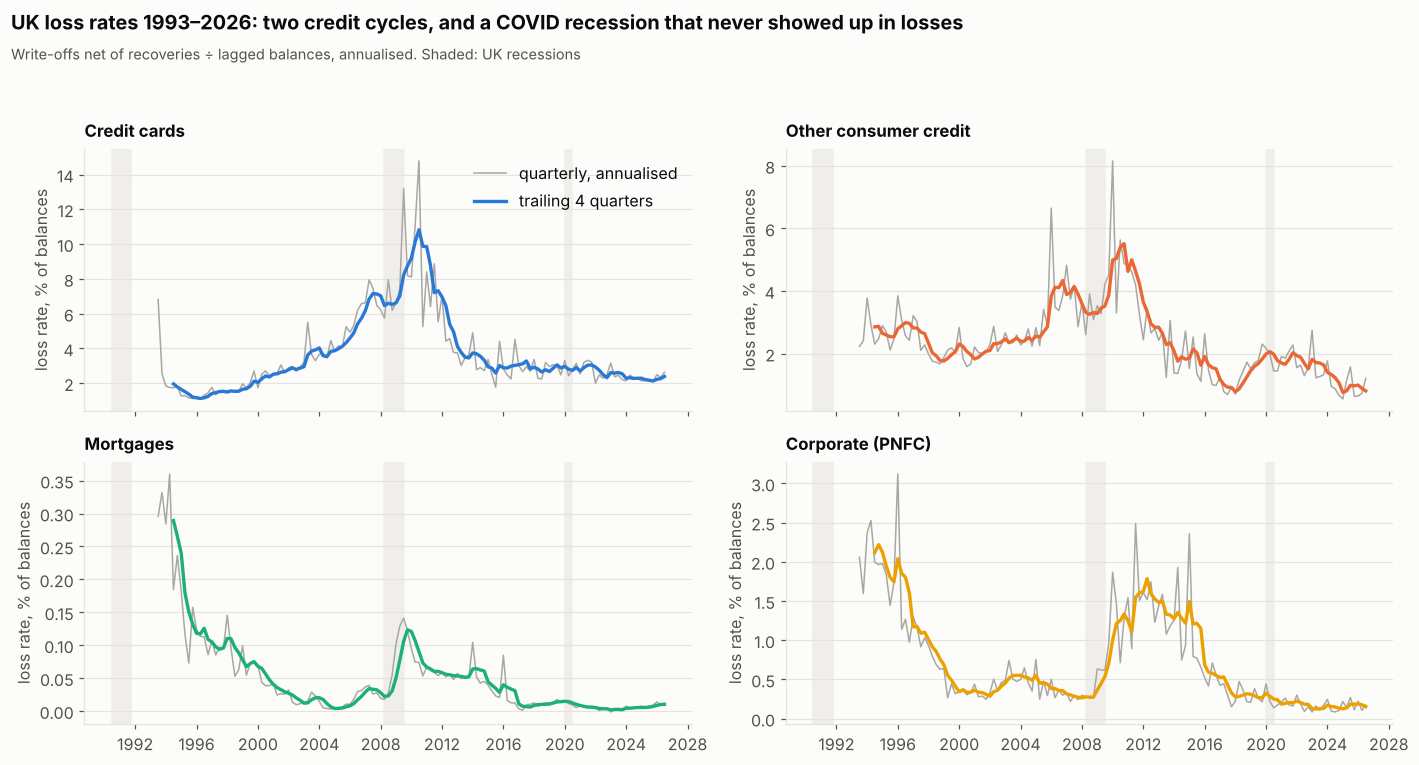

In [6]:
def trailing_rate(p: str) -> pd.Series:
    wo = panel[f"wo_{p}"].rolling(4).sum()
    avg_bal = panel[f"bal_{p}"].shift(1).rolling(4).mean()
    return 100 * wo / avg_bal

lr4 = pd.DataFrame({p: trailing_rate(p) for p in PORTFOLIOS})

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, p in zip(axes.flat, PORTFOLIOS):
    shade_recessions(ax)
    ax.plot(t, lr[p], color=GREY, lw=1, label="quarterly, annualised")
    ax.plot(t, lr4[p], color=PORTFOLIO_COLOURS[p], lw=2.2, label="trailing 4 quarters")
    ax.set_title(LABEL[p], fontsize=11, pad=8)
    ax.set_ylabel("loss rate, % of balances")
axes[0, 0].legend(loc="upper right")
fig_title(fig, "UK loss rates 1993–2026: two credit cycles, and a COVID recession that never showed up in losses",
          "Write-offs net of recoveries ÷ lagged balances, annualised. Shaded: UK recessions")
save(fig, "01_loss_rates_history")
fig

## 3. What happened in each downturn?

In [7]:
episodes = {
    "Early-1990s tail (1993)": ("1993Q2", "1994Q4"),
    "Pre-crisis boom (2004–06)": ("2004Q1", "2006Q4"),
    "Global financial crisis (2009–11)": ("2009Q1", "2011Q4"),
    "Post-crisis low (2017–19)": ("2017Q1", "2019Q4"),
    "COVID (2020–21)": ("2020Q1", "2021Q4"),
    "Rate shock (2023–24)": ("2023Q1", "2024Q4"),
}
rows = []
for name, (a, b) in episodes.items():
    w = panel.loc[a:b]
    rows.append({"episode": name, **{LABEL[p]: lr4.loc[a:b, p].max() for p in PORTFOLIOS},
                 "peak unemployment": w.unemployment.max(), "min GDP growth y/y": w.gdp_growth_yoy.min(),
                 "peak Bank Rate": w.bank_rate.max()})
ep = pd.DataFrame(rows).set_index("episode")
ep.round(2)

,Credit cards,Other consumer credit,Mortgages,Corporate (PNFC),peak unemployment,min GDP growth y/y,peak Bank Rate
episode,,,,,,,
Early-1990s tail (1993),1.96,2.87,0.29,2.22,10.4,2.23,5.88
Pre-crisis boom (2004–06),6.17,4.34,0.03,0.55,5.5,1.14,4.89
Global financial crisis (2009–11),10.83,5.51,0.12,1.62,8.4,-6.18,1.07
Post-crisis low (2017–19),3.28,1.99,0.01,0.53,4.6,0.74,0.75
COVID (2020–21),3.05,2.06,0.01,0.28,5.3,-21.67,0.61
Rate shock (2023–24),2.62,1.72,0.01,0.17,4.4,-0.46,5.25


**Reading:**
- **Cards and other consumer credit** carry almost all the household credit risk.
- **UK card losses were already high before the crisis.** The trailing card loss rate reached about 6% in 2004–06, with unemployment near 5% and GDP growing. That matches the mid-2000s surge in UK personal insolvencies (IVAs) after the 2004 bankruptcy reforms: a supply-side credit cycle the macro data cannot see. Card losses then rose a further ~1.8x to the 2009–11 peak. **Decision:** a pure macro model will under-fit 2004–07, so test a credit-cycle variable (card balance growth two years earlier) and report the period as a known limitation.
- **Mortgages** barely register: about 0.12% at the 2009–11 peak and 0.3% in the 1993 tail of the early-1990s housing crash, despite large house price falls. UK mortgage losses are cushioned by equity and forbearance, so a regression on them will be dominated by noise. **Decision:** keep mortgages in the panel but treat them as a secondary, lower-confidence model.
- **COVID is the key anomaly:** GDP fell about 20% year on year, yet loss rates *fell*. Furlough, payment holidays and forced saving broke the usual link between output and defaults. A model fitted through 2020 without accounting for this will under-react to GDP. **Decision:** treat 2020Q1–2021Q4 as a policy-intervention regime (dummy, or exclusion tested both ways).
- **The 2023–24 rate shock** (Bank Rate 5.25%) did not raise realised losses, which is relevant because the 2025 scenario's main new feature is an 8% Bank Rate.

## 4. Which economic variables lead losses, and by how much?
Cross-correlation of the trailing card loss rate with each driver at leads of 0–8 quarters (driver at *t − k* versus losses at *t*). COVID quarters are excluded so the regime break does not dominate the correlations.

In [8]:
drivers = {
    "unemployment": "Unemployment rate",
    "unemployment_chg_yoy": "Change in unemployment, y/y",
    "gdp_growth_yoy": "Real GDP growth, y/y",
    "house_price_growth_yoy": "House price growth, y/y",
    "bank_rate": "Bank Rate",
    "cpi_inflation": "CPI inflation",
}
ex_covid = ~panel.index.to_series().between(pd.Period("2020Q1"), pd.Period("2021Q4"))

def lead_corr(target: pd.Series, driver: pd.Series, max_lag: int = 8) -> pd.Series:
    return pd.Series({k: target[ex_covid].corr(driver.shift(k)[ex_covid]) for k in range(max_lag + 1)})

cc = {p: pd.DataFrame({drivers[d]: lead_corr(lr4[p], panel[d]) for d in drivers}) for p in PORTFOLIOS}
best = pd.DataFrame({LABEL[p]: [f"{cc[p][c].abs().idxmax()}q (r = {cc[p][c][cc[p][c].abs().idxmax()]:+.2f})"
                                 for c in cc[p]] for p in PORTFOLIOS}, index=cc["credit_card"].columns)
best

,Credit cards,Other consumer credit,Mortgages,Corporate (PNFC)
Unemployment rate,0q (r = +0.25),0q (r = +0.58),2q (r = +0.86),4q (r = +0.94)
"Change in unemployment, y/y",3q (r = +0.70),4q (r = +0.52),0q (r = -0.21),0q (r = -0.35)
"Real GDP growth, y/y",2q (r = -0.47),4q (r = -0.29),3q (r = -0.14),5q (r = -0.17)
"House price growth, y/y",4q (r = -0.28),5q (r = -0.25),5q (r = -0.41),8q (r = -0.52)
Bank Rate,0q (r = -0.41),8q (r = +0.28),8q (r = +0.43),1q (r = -0.10)
CPI inflation,0q (r = +0.11),8q (r = -0.14),0q (r = -0.18),0q (r = -0.14)


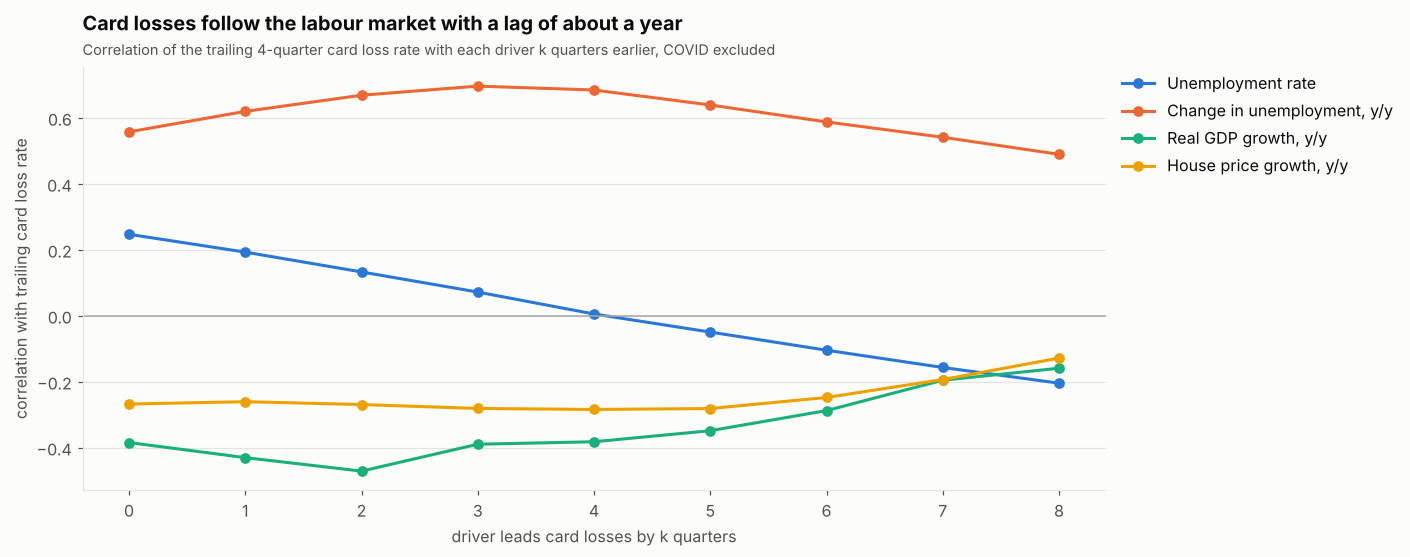

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
for d, colour in zip(["Unemployment rate", "Change in unemployment, y/y", "Real GDP growth, y/y",
                      "House price growth, y/y"], [BLUE, ORANGE, "#1baf7a", "#eda100"]):
    ax.plot(cc["credit_card"].index, cc["credit_card"][d], marker="o", ms=6, color=colour, label=d)
ax.axhline(0, color=GREY, lw=1)
ax.set_xlabel("driver leads card losses by k quarters")
ax.set_ylabel("correlation with trailing card loss rate")
ax.set_title("Card losses follow the labour market with a lag of about a year")
subtitle(ax, "Correlation of the trailing 4-quarter card loss rate with each driver k quarters earlier, COVID excluded")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
save(fig, "01_lead_lag_cards")
fig

## 5. Stationarity: can we regress levels on levels?
Regressing one trending series on another can produce a high R² with no real relationship (a *spurious regression*). Two complementary tests:
- **ADF:** null hypothesis = unit root (non-stationary). Small p-value → stationary.
- **KPSS:** null hypothesis = stationary. Small p-value → non-stationary.

When the two disagree, the series is borderline, which is common with only ~130 quarters.

In [10]:
def stationarity(s: pd.Series) -> dict:
    s = s.dropna()
    return {"ADF p": adfuller(s, autolag="AIC")[1], "KPSS p": kpss(s, regression="c", nlags="auto")[1]}

tests = {}
for p in PORTFOLIOS:
    tests[f"{LABEL[p]} loss rate (4q)"] = stationarity(lr4[p])
    tests[f"  Δ {LABEL[p]} loss rate"] = stationarity(lr4[p].diff())
for d in ["unemployment", "gdp_growth_yoy", "house_price_growth_yoy", "bank_rate", "unemployment_chg_yoy"]:
    tests[drivers[d]] = stationarity(panel[d])
st = pd.DataFrame(tests).T
st["verdict"] = np.select(
    [(st["ADF p"] < 0.05) & (st["KPSS p"] > 0.05), (st["ADF p"] > 0.05) & (st["KPSS p"] < 0.05)],
    ["stationary", "non-stationary"], "borderline")
st.round(3)

,ADF p,KPSS p,verdict
Credit cards loss rate (4q),0.373,0.096,borderline
Δ Credit cards loss rate,0.000,0.100,stationary
Other consumer credit loss rate (4q),0.535,0.023,non-stationary
Δ Other consumer credit loss rate,0.092,0.100,borderline
Mortgages loss rate (4q),0.293,0.010,non-stationary
Δ Mortgages loss rate,0.009,0.050,borderline
Corporate (PNFC) loss rate (4q),0.210,0.045,non-stationary
Δ Corporate (PNFC) loss rate,0.044,0.100,stationary
Unemployment rate,0.060,0.010,non-stationary
"Real GDP growth, y/y",0.000,0.100,stationary


**Decision:** loss-rate *levels* and the unemployment *level* are persistent and at best borderline stationary over this sample, while their changes are stationary. Notebook 03 therefore compares (a) a levels model whose residuals must pass a cointegration (Engle–Granger) test, against (b) a model in changes. Bank practice favours levels models because stress projections need a loss *level*, but only if the residuals are stationary.

## 6. Distribution of the target
Loss rates are bounded below by zero and right-skewed. A linear model on the raw rate can predict negative losses in a benign scenario and understates the upside in a severe one. The **logit** transform maps a rate in (0, 1) onto the whole real line; the log is a simpler alternative.

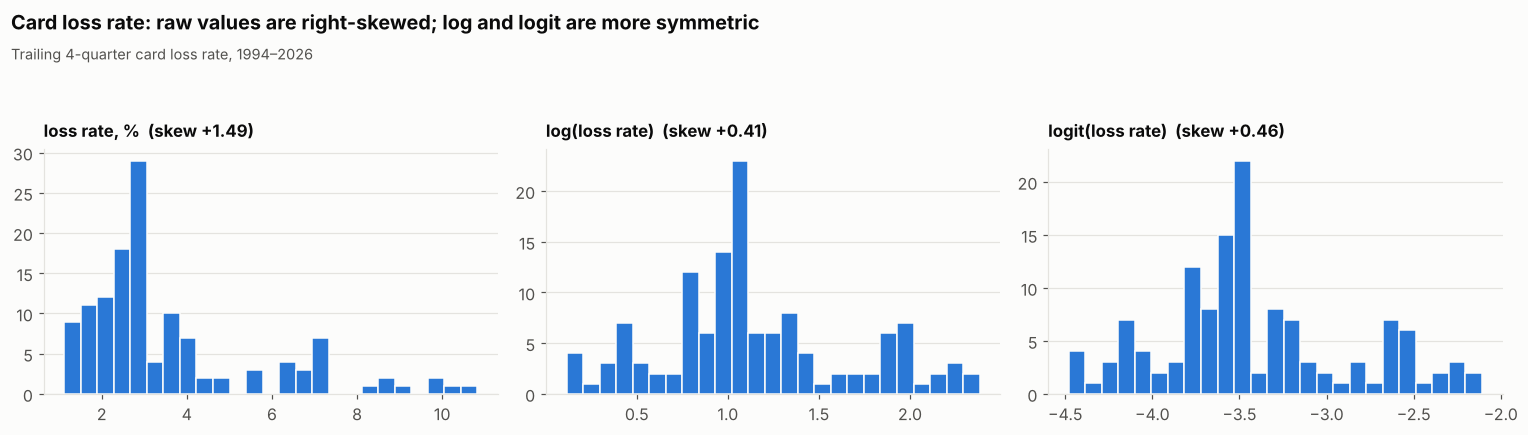

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
s = lr4["credit_card"].dropna()
for ax, (vals, name) in zip(axes, [(s, "loss rate, %"), (np.log(s), "log(loss rate)"),
                                    (np.log((s / 100) / (1 - s / 100)), "logit(loss rate)")]):
    ax.hist(vals, bins=25, color=BLUE, edgecolor="#fcfcfb")
    ax.set_title(f"{name}  (skew {pd.Series(vals).skew():+.2f})", fontsize=11, pad=8)
fig_title(fig, "Card loss rate: raw values are right-skewed; log and logit are more symmetric",
          "Trailing 4-quarter card loss rate, 1994–2026")
save(fig, "01_target_distribution")
fig

## 7. Does the 2025 stress scenario ask the model to extrapolate?
A regression is only trustworthy inside the range of the data it was fitted on. The scenario is compared with the **1993–2026 history used for fitting**.

In [12]:
bcst = read_bcst_paths(BCST_PATHS_FILE)
sc = pd.DataFrame(index=bcst.index)
sc["unemployment"] = bcst["UK unemployment rate"]
sc["gdp_growth_yoy"] = 100 * bcst["UK real GDP"].pct_change(4)
sc["house_price_growth_yoy"] = 100 * bcst["UK residential property price index"].pct_change(4)
sc["bank_rate"] = bcst["Bank Rate"]
sc["cpi_inflation"] = 100 * bcst["UK CPI"].pct_change(4)
scen = sc[bcst.is_projection]

compare = pd.DataFrame({
    "history min": panel[list(sc.columns)].min(),
    "history max": panel[list(sc.columns)].max(),
    "scenario min": scen.min(),
    "scenario max": scen.max(),
}).rename(index=drivers)
compare["outside history?"] = np.where(
    (compare["scenario max"] > compare["history max"]) | (compare["scenario min"] < compare["history min"]),
    "YES", "no")
compare.round(1)

,history min,history max,scenario min,scenario max,outside history?
Unemployment rate,3.7,10.4,4.9,8.5,no
"Real GDP growth, y/y",-21.7,25.5,-4.6,1.4,no
"House price growth, y/y",-15.5,25.1,-12.6,7.4,no
Bank Rate,0.1,7.5,3.0,8.0,YES
CPI inflation,0.0,10.7,2.0,10.0,no


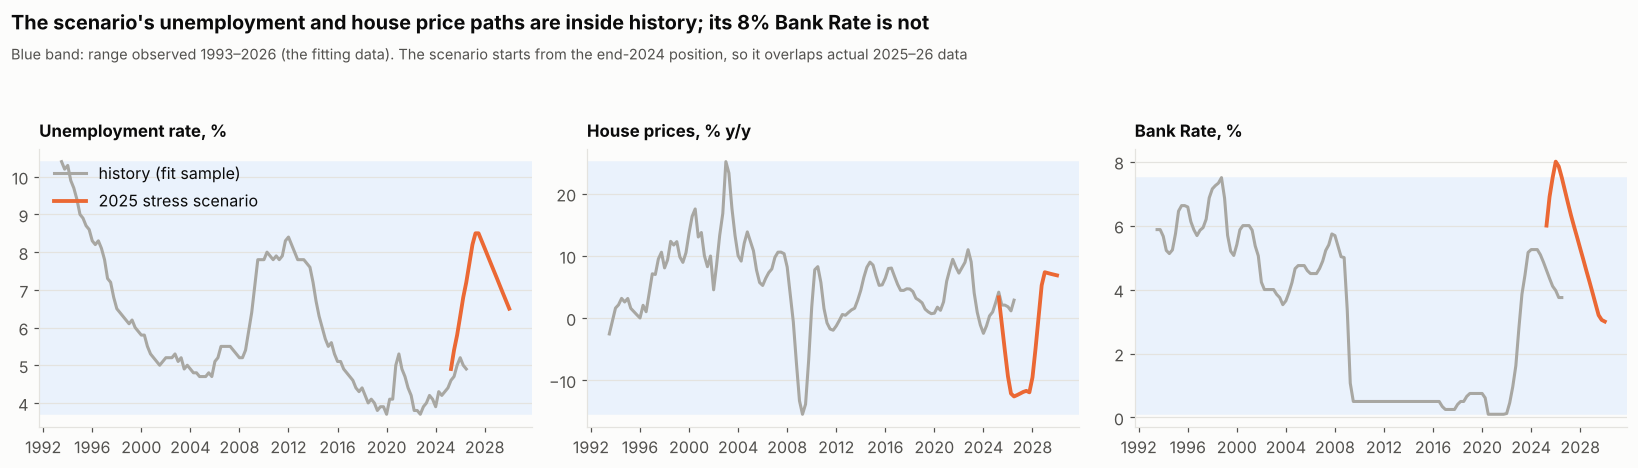

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharex=True)
for ax, (col, ttl) in zip(axes, [("unemployment", "Unemployment rate, %"), ("house_price_growth_yoy", "House prices, % y/y"),
                                 ("bank_rate", "Bank Rate, %")]):
    ax.plot(t, panel[col], color=GREY, label="history (fit sample)")
    ax.plot(scen.index.to_timestamp(how="end"), scen[col], color=ORANGE, lw=2.5, label="2025 stress scenario")
    ax.axhspan(panel[col].min(), panel[col].max(), color="#eaf2fc", zorder=0)
    ax.set_title(ttl, fontsize=11, pad=8)
axes[0].legend(loc="upper left")
fig_title(fig, "The scenario's unemployment and house price paths are inside history; its 8% Bank Rate is not",
          "Blue band: range observed 1993–2026 (the fitting data). The scenario starts from the end-2024 position, so it overlaps actual 2025–26 data")
save(fig, "01_scenario_vs_history")
fig

## 8. Cross-check: do my macro series match the Bank of England's own history?
The scenario is expressed relative to the Bank's historical data. If my ONS / Land Registry history used different definitions, the projections would start from the wrong place.

In [14]:
hist = sc[~bcst.is_projection]
chk = {}
for col in ["unemployment", "gdp_growth_yoy", "house_price_growth_yoy", "bank_rate", "cpi_inflation"]:
    both = pd.concat([panel[col], hist[col]], axis=1, keys=["mine", "boe"]).dropna()
    chk[drivers[col]] = {"quarters": len(both), "correlation": both.corr().iloc[0, 1],
                         "mean abs difference": (both.mine - both.boe).abs().mean()}
pd.DataFrame(chk).T.round(3)

,quarters,correlation,mean abs difference
Unemployment rate,100.0,1.000,0.000
"Real GDP growth, y/y",96.0,0.998,0.214
"House price growth, y/y",96.0,0.995,0.269
Bank Rate,100.0,1.000,0.001
CPI inflation,96.0,1.000,0.047


## Findings and decisions

The table below is generated from the numbers above (see the next cell), then interpreted.

In [15]:
card_peak = ep.loc["Global financial crisis (2009–11)", "Credit cards"]
card_calm = ep.loc["Pre-crisis boom (2004–06)", "Credit cards"]
lead_u = cc["credit_card"]["Change in unemployment, y/y"].idxmax()
covid = ep.loc["COVID (2020–21)"]
print(f"Card loss rate: {card_calm:.1f}% (2004–06 peak) -> {card_peak:.1f}% (2009–11 peak), x{card_peak / card_calm:.1f}")
print(f"Mortgage loss rate peak (GFC): {ep.loc['Global financial crisis (2009–11)', 'Mortgages']:.2f}%")
print(f"COVID: min GDP growth {covid['min GDP growth y/y']:.1f}% y/y, card loss peak {covid['Credit cards']:.2f}%")
print(f"Change in unemployment leads card losses by {lead_u} quarters "
      f"(r = {cc['credit_card']['Change in unemployment, y/y'].max():+.2f})")
print("Scenario variables outside fitted history:", ", ".join(compare.index[compare['outside history?'] == 'YES']) or "none")
print(f"Balance breaks >10% q/q: {len(breaks)}; write-off spikes (robust z > 4): {len(spikes)}")

Card loss rate: 6.2% (2004–06 peak) -> 10.8% (2009–11 peak), x1.8
Mortgage loss rate peak (GFC): 0.12%
COVID: min GDP growth -21.7% y/y, card loss peak 3.05%
Change in unemployment leads card losses by 3 quarters (r = +0.70)
Scenario variables outside fitted history: Bank Rate
Balance breaks >10% q/q: 12; write-off spikes (robust z > 4): 26
